# PHASE 3 : EXPLORATORY DATA ANALYSIS (EDA)

In [41]:
# Import the prerequisits
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [43]:
df = pd.read_csv(r"C:\Users\Aditya\OneDrive\Documents\Intershala Data\Pyhton\Deep Learning\Data Cleaning\Books_cleaned_dataset.csv")
df.head

<bound method NDFrame.head of                                                  Title     Genre  Price  \
0                              It's Only the Himalayas    Travel  45.17   
1    Full Moon over Noah’s Ark: An Odyssey to Mount...    Travel  49.43   
2    See America: A Celebration of Our National Par...    Travel  48.87   
3    Vagabonding: An Uncommon Guide to the Art of L...    Travel  36.94   
4                                 Under the Tuscan Sun    Travel  37.33   
..                                                 ...       ...    ...   
995  Why the Right Went Wrong: Conservatism--From G...  Politics  52.65   
996  Equal Is Unfair: America's Misguided Fight Aga...  Politics  56.86   
997                                     Amid the Chaos  Cultural  36.58   
998                                         Dark Notes   Erotica  19.19   
999  The Long Shadow of Small Ghosts: Murder and Me...     Crime  10.97   

    Price_Band  Rating  Rating_Percent  Title_Length  
0         High

### Objective
    Explore, visualize, and interpret patterns, trends, and anomalies in book pricing, ratings, and genres.

#### Summary Statistics

In [46]:
# summary
df.describe()

,Price,Rating,Rating_Percent,Title_Length
count,1000.00000,1000.000000,1000.000000,1000.000000
mean,35.07035,2.923000,58.460000,39.097000
std,14.44669,1.434967,28.699339,25.752724
min,10.00000,1.000000,20.000000,2.000000
25%,22.10750,2.000000,40.000000,19.000000
50%,35.98000,3.000000,60.000000,35.000000
75%,47.45750,4.000000,80.000000,53.000000
max,59.99000,5.000000,100.000000,204.000000


Summary statistics were computed to understand the central tendency and dispersion of price, rating, and derived features.

In [48]:
# Median
df[['Price', 'Rating', 'Rating_Percent']].median()

Price             35.98
Rating             3.00
Rating_Percent    60.00
dtype: float64

The median book price is lower than the mean, indicating a left-skewed price distribution.

#### Trend Analysis

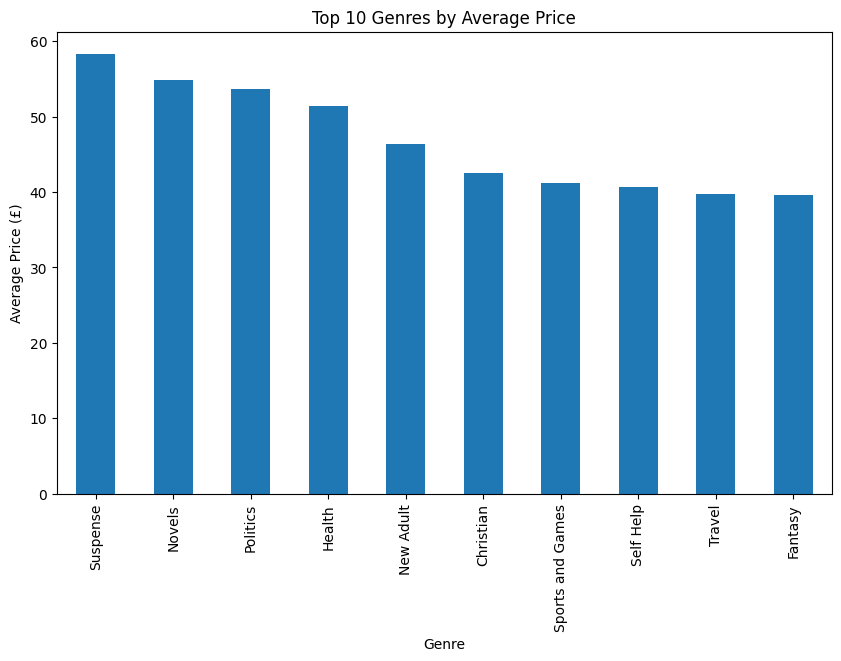

In [51]:
# Genre wise Average Price
genre_price = df.groupby('Genre')['Price'].mean().sort_values(ascending=False).round(2)

plt.figure(figsize=(10,6))
genre_price.head(10).plot(kind="bar")
plt.title("Top 10 Genres by Average Price")
plt.ylabel("Average Price (£)")
plt.show()

Certain genres command significantly higher average prices, suggesting niche or premium content.

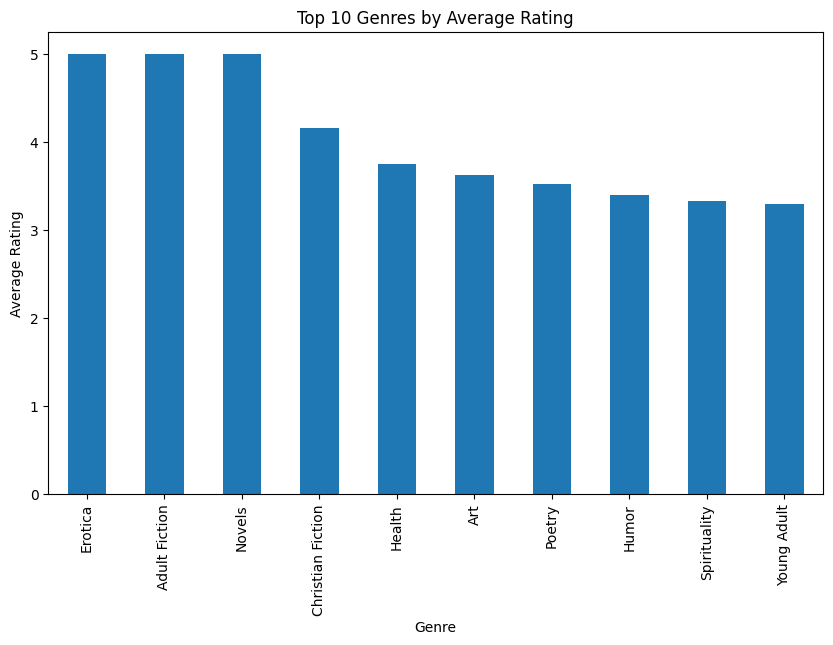

In [53]:
# Genre wise Average Rating
genre_rating = df.groupby('Genre')['Rating'].mean().sort_values(ascending=False)

plt.figure(figsize=(10,6))
genre_rating.head(10).plot(kind="bar")
plt.title("Top 10 Genres by Average Rating")
plt.ylabel("Average Rating")
plt.show()

Certain genres such as Adult Fiction and Novels exhibit higher average ratings, indicating stronger reader appreciation. However, genre-level averages vary, suggesting that reader preferences are genre-specific rather than uniform across categories.

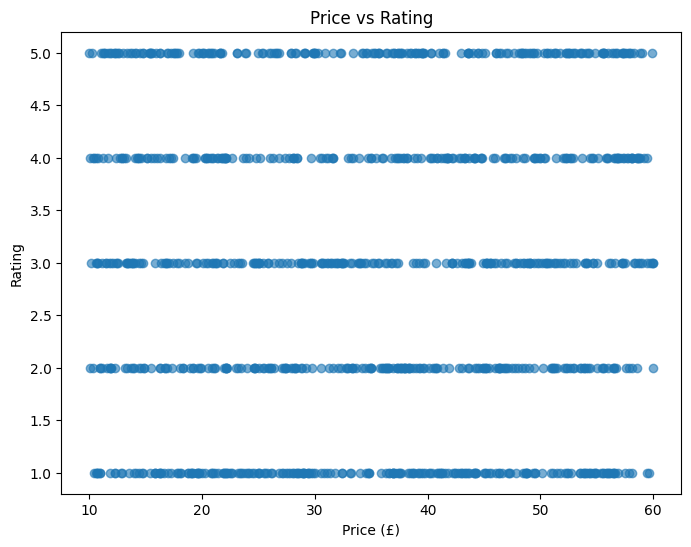

In [55]:
# Price vs Rating
plt.figure(figsize=(8,6))
plt.scatter(df["Price"], df["Rating"], alpha=0.6)
plt.xlabel("Price (£)")
plt.ylabel("Rating")
plt.title("Price vs Rating")
plt.show()

The scatter plot shows no strong linear relationship between price and rating. Books across all price ranges receive a wide spread of ratings, indicating that higher price does not guarantee higher user ratings.

#### Visualization

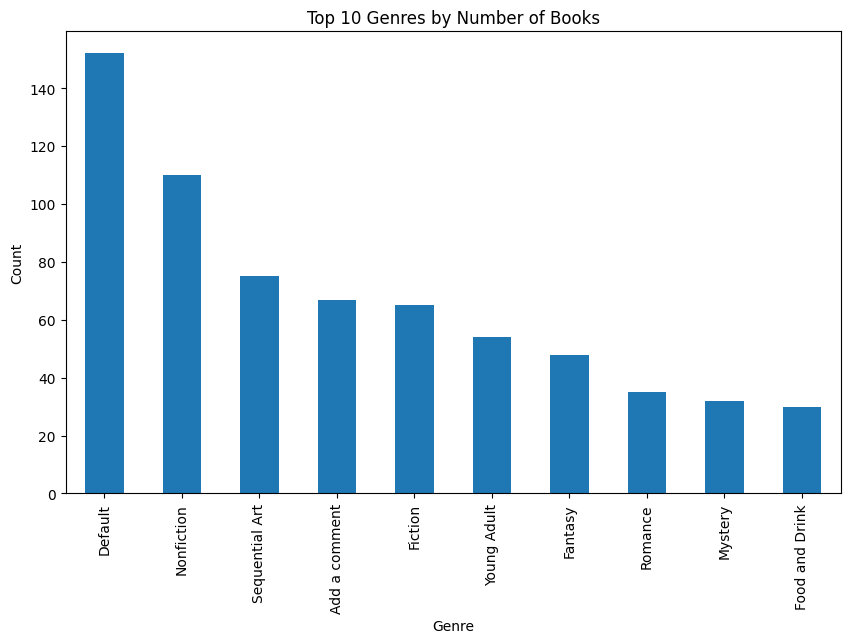

In [25]:
# Books per Genre
genre_count = df['Genre'].value_counts()

plt.figure(figsize=(10,6))
genre_count.head(10).plot(kind = 'bar')
plt.title('Top 10 Genres by Number of Books')
plt.ylabel('Count')
plt.show()

Some genres dominate the dataset, indicating higher content availability and possibly higher demand.

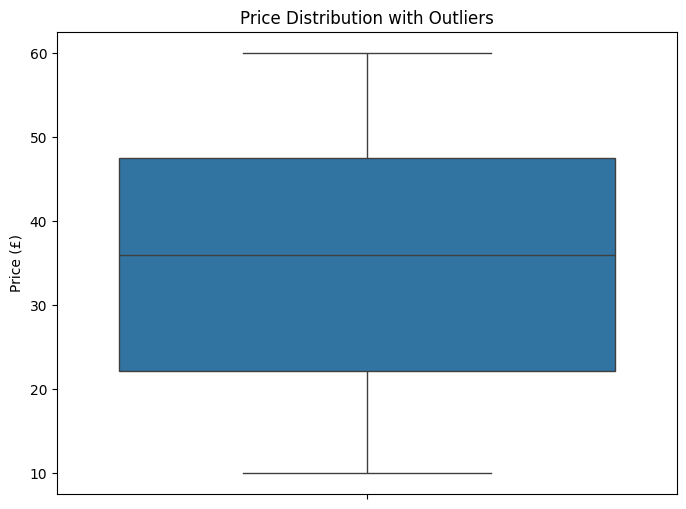

In [28]:
# Boxplot - Price Distribution
plt.figure(figsize=(8,6))
sns.boxplot(y = df['Price'])
plt.title('Price Distribution with Outliers')
plt.ylabel('Price (£)')
plt.show()

The boxplot reveals a moderately spread price distribution with a median around £35. The absence of extreme outliers suggests consistent pricing, while a slight right skew indicates the presence of higher-priced books.

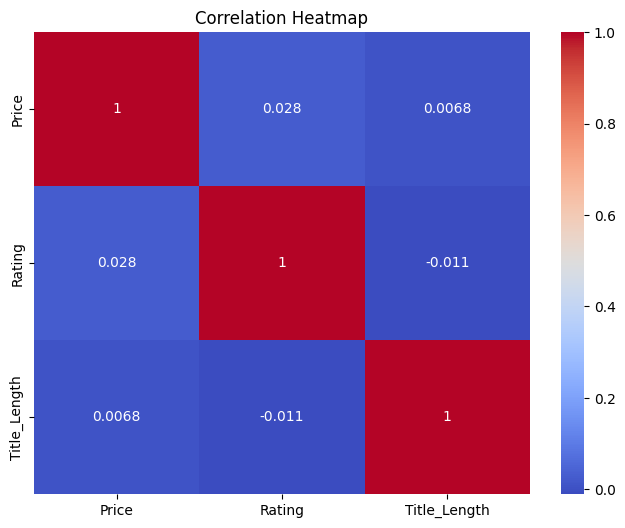

In [31]:
# Correlation Analysis
corr = df[["Price", "Rating", "Title_Length"]].corr()

plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

The correlation heatmap indicates negligible relationships between price, rating, and title length, confirming that book ratings are largely independent of pricing. The correlation heatmap indicates negligible relationships between price, rating, and title length, confirming that book ratings are largely independent of pricing.

#### Trend, Pattern and Anomalies

##### Key Findings:
    1. Price Distribution
        Right Skewed with premium outliers
        
    2. Rating
        Most books are rated 3-5
        
    3. Genre Trends
        Some genres dominate in volume but not in rating
        
    4. Price vs Rating
        No strong correlation
        
    5. Outliers
        High-priced books exist without proportionally higher ratings